# Menjalankan notebook di VS Code

Notebook ini mempertahankan urutan dan metode dari notebook acuan penelitian: **A. Analisis Tren Waktu, B. Analisis Regional, dan C. Ringkasan Terpadu**. Perubahan dilakukan terutama untuk kompatibilitas VS Code, validasi data, dan penanganan beberapa kasus statistik.

## Persiapan

1. Simpan dataset Excel pada `data/raw/Dataset E-Commerce.xlsx` atau di folder proyek dengan nama `Dataset E-Commerce.xlsx`.
2. Dari terminal VS Code, aktifkan virtual environment lalu instal dependensi:

   ```powershell
   pip install -r requirements.txt
   ```

3. Pilih kernel `.venv` di kanan atas notebook.
4. Jalankan sel dari atas ke bawah.

Notebook ini tidak melakukan clustering, sesuai rancangan penelitian. Choropleth bersifat opsional dan memerlukan file batas provinsi GeoJSON yang disiapkan terpisah.

**Batasan interpretasi:** indeks Google Trends 0–100 adalah relatif. Jika tiap platform dinormalisasi sendiri, level antarplatform tidak boleh langsung ditafsirkan sebagai perbandingan minat absolut.

# Digital Consumer Interest in Indonesian E-Commerce
### A Google Trends Analysis of Temporal and Regional Search Patterns, 2020–2025

Notebook ini berisi kode analisis untuk dua bagian penelitian:

| Bagian | Sheet | Isi |
|---|---|---|
| **A. Analisis Tren Waktu** | `Time Series` | deskriptif, tren (Mann-Kendall), pertumbuhan (YoY, CAGR), musiman (STL), *structural break*, korelasi & cross-correlation |
| **B. Analisis Regional** | `Regional` | peringkat, heatmap, platform dominan, variasi (CV), uji Friedman, Jawa vs luar Jawa, korelasi antarplatform |
| **C. Ringkasan** | – | tabel ringkasan terpadu + ekspor hasil |

**Tanpa clustering**, sesuai rancangan penelitian.

> ⚠️ **Catatan penting interpretasi.** Nilai Google Trends adalah indeks 0–100 *relatif*. Pada dataset ini setiap platform tampaknya dinormalisasi terhadap puncaknya sendiri (semua kolom bernilai maksimum 100). Karena itu, **perbandingan level antarplatform tidak valid** kecuali data diunduh ulang dalam satu kueri perbandingan. Notebook ini mengutamakan analisis *pola, tren, dan perubahan* per platform, bukan perbandingan level.

## 0. Persiapan

In [1]:
# Instal dependensi dari terminal VS Code, bukan dari sel notebook:
# pip install -r requirements.txt
# Setelah instalasi, pilih kernel Python dari environment .venv.
print("Pastikan dependensi sudah diinstal dan kernel .venv dipilih sebelum melanjutkan.")

Pastikan dependensi sudah diinstal dan kernel .venv dipilih sebelum melanjutkan.


In [2]:
import warnings
from pathlib import Path
import os

# Jangan menyembunyikan semua warning; warning tertentu dapat menunjukkan isu kompatibilitas.
warnings.filterwarnings("default")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pymannkendall as mk
import ruptures as rpt
from statsmodels.tsa.seasonal import STL
from statsmodels.stats.multitest import multipletests
from itertools import combinations

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# ---------------- KONFIGURASI PROYEK ----------------
PLATFORMS = ["Shopee", "Tokopedia", "Lazada", "Blibli", "TikTok Shop"]
COLORS = dict(zip(PLATFORMS, ["#EE4D2D", "#42B549", "#0F146D", "#0095DA", "#111111"]))
TIKTOK_START = pd.Timestamp("2021-09-01")

EVENTS = {
    "Larangan social commerce (Permendag 31/2023)": "2023-10-01",
    "Integrasi Tokopedia–TikTok Shop": "2023-12-01",
}

# Cari dataset di struktur proyek VS Code maupun di folder kerja saat ini.
cwd = Path.cwd().resolve()
candidate_paths = [
    cwd / "data" / "raw" / "Dataset E-Commerce.xlsx",
    cwd / "Dataset E-Commerce.xlsx",
    cwd.parent / "data" / "raw" / "Dataset E-Commerce.xlsx",
    cwd.parent / "Dataset E-Commerce.xlsx",
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), candidate_paths[0])

# Output berada di folder proyek; jika notebook dijalankan dari notebooks/, naik satu tingkat.
PROJECT_DIR = cwd.parent if cwd.name.lower() == "notebooks" else cwd
OUT_DIR = PROJECT_DIR / "output_analisis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(OUT_DIR / name, bbox_inches="tight", dpi=200)

print("Folder kerja :", cwd)
print("Dataset      :", DATA_PATH)
print("Dataset ada  :", DATA_PATH.exists())
print("Folder output:", OUT_DIR)
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset Excel tidak ditemukan. Simpan file di "
        "'data/raw/Dataset E-Commerce.xlsx' atau di folder utama proyek."
    )

Folder kerja : D:\Interest in Indonesian E-Commerce\notebooks
Dataset      : D:\Interest in Indonesian E-Commerce\data\raw\Dataset E-Commerce.xlsx
Dataset ada  : True
Folder output: D:\Interest in Indonesian E-Commerce\output_analisis


## 1. Memuat dan Membersihkan Data

In [3]:
def load_sheet(sheet):
    df = pd.read_excel(DATA_PATH, sheet_name=sheet, header=2)
    df = df.dropna(how="all").dropna(axis=1, how="all")
    df.columns = [str(c).strip() for c in df.columns]
    df = df.rename(columns={"Tiktok Shop": "TikTok Shop", "Tiktok shop": "TikTok Shop"})
    return df

ts_raw = load_sheet("Time Series")
reg_raw = load_sheet("Regional")

for sheet_name, df in [("Time Series", ts_raw), ("Regional", reg_raw)]:
    missing_columns = [p for p in PLATFORMS if p not in df.columns]
    if missing_columns:
        raise ValueError(f"Kolom platform tidak ditemukan pada {sheet_name}: {missing_columns}")

if "Kode Periode" not in ts_raw.columns:
    raise ValueError("Kolom 'Kode Periode' tidak ditemukan.")
if "Wilayah" not in reg_raw.columns:
    raise ValueError("Kolom 'Wilayah' tidak ditemukan.")

ts_raw["Kode Periode"] = pd.to_datetime(ts_raw["Kode Periode"], errors="coerce")
if ts_raw["Kode Periode"].isna().any():
    raise ValueError("Ada tanggal kosong/tidak valid di Time Series.")
if ts_raw["Kode Periode"].duplicated().any():
    raise ValueError("Ada tanggal duplikat di Time Series.")

for p in PLATFORMS:
    ts_raw[p] = pd.to_numeric(ts_raw[p], errors="coerce")
    reg_raw[p] = pd.to_numeric(reg_raw[p], errors="coerce")

if ts_raw[PLATFORMS].isna().any().any():
    raise ValueError("Ada nilai kosong/nonnumerik di Time Series; periksa sumber sebelum imputasi.")
if reg_raw[PLATFORMS].isna().any().any():
    raise ValueError("Ada nilai kosong/nonnumerik di Regional; periksa sumber sebelum imputasi.")

ts = ts_raw.set_index("Kode Periode").sort_index()
expected_dates = pd.date_range("2020-01-01", "2025-12-01", freq="MS")
if not ts.index.equals(expected_dates):
    raise ValueError("Time Series harus lengkap bulanan Januari 2020–Desember 2025.")

reg_raw["Wilayah"] = reg_raw["Wilayah"].astype("string").str.strip()
if reg_raw["Wilayah"].isna().any() or reg_raw["Wilayah"].eq("").any():
    raise ValueError("Ada nama wilayah kosong.")
if reg_raw["Wilayah"].duplicated().any():
    raise ValueError("Ada nama wilayah duplikat.")

reg = reg_raw.set_index("Wilayah")[PLATFORMS].copy()
if len(reg) != 34:
    raise ValueError(f"Jumlah wilayah {len(reg)}, seharusnya 34 provinsi.")

for label, df in [("Time Series", ts), ("Regional", reg)]:
    if not df[PLATFORMS].apply(lambda s: s.between(0, 100).all()).all():
        raise ValueError(f"Ada indeks di luar rentang 0–100 pada {label}.")

print("Time series :", ts.shape, "|", ts.index.min().date(), "→", ts.index.max().date())
print("Regional    :", reg.shape)
print("Missing TS  :", int(ts[PLATFORMS].isna().sum().sum()),
      "| Missing Regional:", int(reg[PLATFORMS].isna().sum().sum()))
display(ts[PLATFORMS].head())

# Seri analisis: TikTok Shop dipotong mulai September 2021.
series = {p: ts[p].copy() for p in PLATFORMS}
series["TikTok Shop"] = series["TikTok Shop"].loc[TIKTOK_START:].copy()
print("TikTok Shop aktif:", len(series["TikTok Shop"]), "observasi sejak", series["TikTok Shop"].index.min().date())

Time series : (72, 8) | 2020-01-01 → 2025-12-01
Regional    : (34, 5)
Missing TS  : 0 | Missing Regional: 0


,Shopee,Tokopedia,Lazada,Blibli,TikTok Shop
Kode Periode,,,,,
2020-01-01,60,74,79,65,0
2020-02-01,62,80,79,53,0
2020-03-01,71,78,80,55,0
2020-04-01,68,79,76,59,0
2020-05-01,94,100,97,70,0


TikTok Shop aktif: 52 observasi sejak 2021-09-01


# BAGIAN A — Analisis Tren Waktu

## A1. Statistik deskriptif dan visualisasi tren

In [4]:
desc_rows = []
for p, s in series.items():
    desc_rows.append({
        "Platform": p,
        "count": s.count(),
        "mean": s.mean(),
        "std": s.std(),
        "min": s.min(),
        "25%": s.quantile(.25),
        "50%": s.median(),
        "75%": s.quantile(.75),
        "max": s.max(),
        "CV (%)": s.std() / s.mean() * 100 if s.mean() else np.nan,
        "Bulan puncak": s.idxmax().strftime("%b %Y"),
    })
desc = pd.DataFrame(desc_rows).set_index("Platform")
display(desc.round(2))

,count,mean,std,min,25%,50%,75%,max,CV (%),Bulan puncak
Platform,,,,,,,,,,
Shopee,72,72.33,12.34,53,61.75,70.5,80.25,100,17.07,Apr 2022
Tokopedia,72,54.32,14.59,29,44.75,51.0,62.25,100,26.86,May 2020
Lazada,72,41.31,21.95,12,24.75,34.5,53.25,97,53.13,May 2020
Blibli,72,67.50,15.30,35,58.50,68.0,76.25,100,22.67,Mar 2022
TikTok Shop,52,49.04,23.36,13,32.00,40.0,67.50,100,47.64,Jun 2023


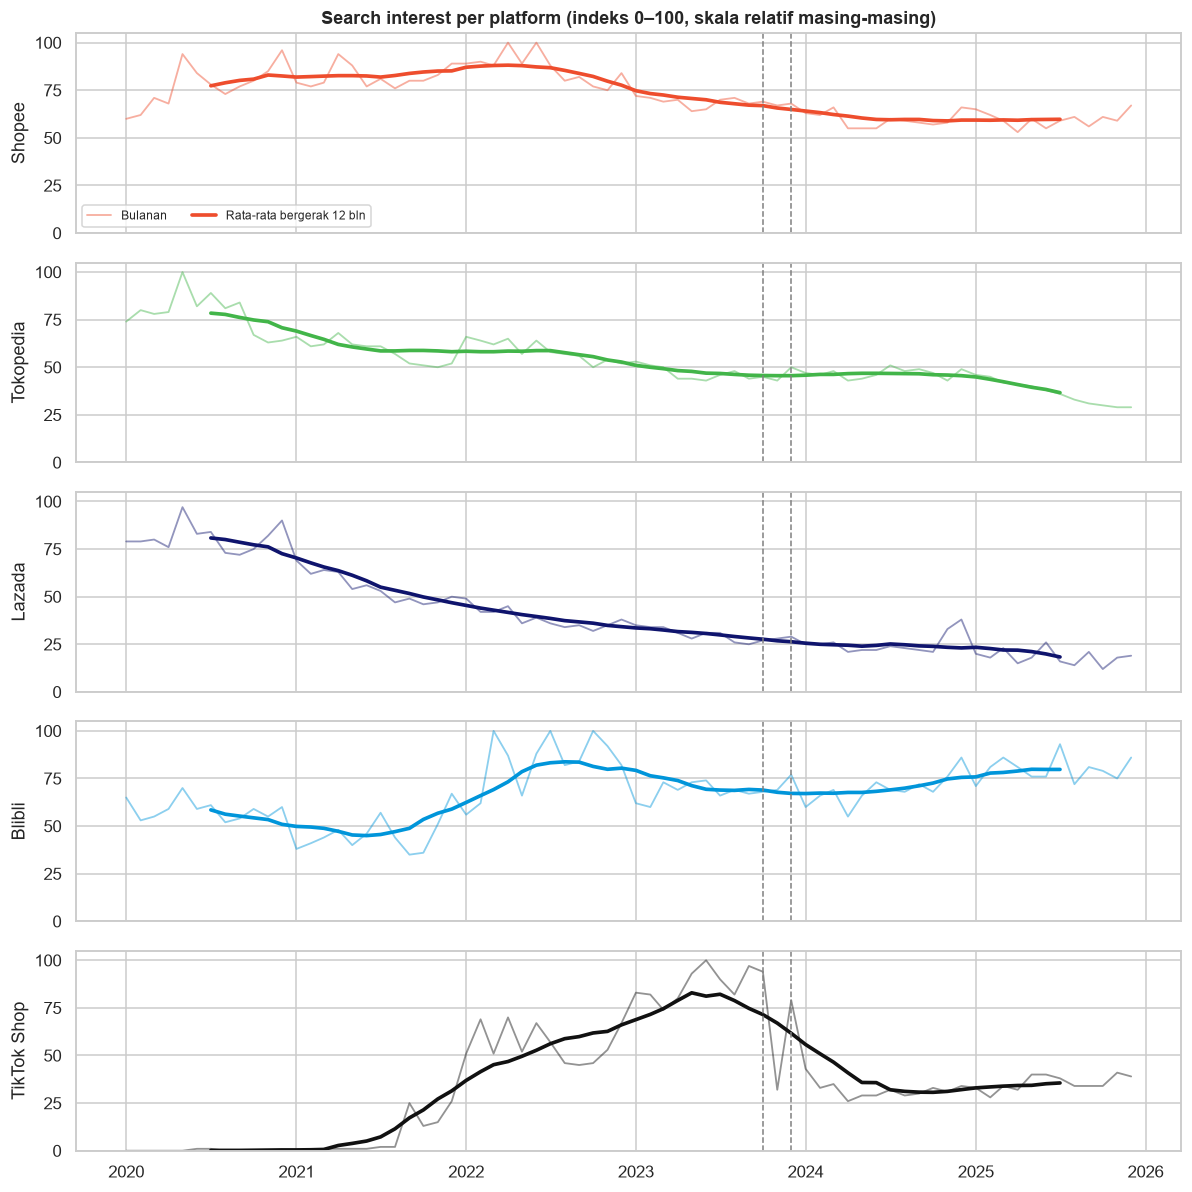

In [5]:
fig, axes = plt.subplots(len(PLATFORMS), 1, figsize=(11, 11), sharex=True)
for ax, p in zip(axes, PLATFORMS):
    s = ts[p]
    ax.plot(s.index, s, color=COLORS[p], alpha=.45, lw=1.2, label="Bulanan")
    ax.plot(s.index, s.rolling(12, center=True).mean(), color=COLORS[p], lw=2.4, label="Rata-rata bergerak 12 bln")
    for name, d in EVENTS.items():
        ax.axvline(pd.Timestamp(d), color="grey", ls="--", lw=1)
    ax.set_ylabel(p); ax.set_ylim(0, 105)
axes[0].legend(loc="lower left", ncol=2, fontsize=8)
axes[0].set_title("Search interest per platform (indeks 0–100, skala relatif masing-masing)")
plt.tight_layout(); savefig("A1_tren_per_platform.png"); plt.show()

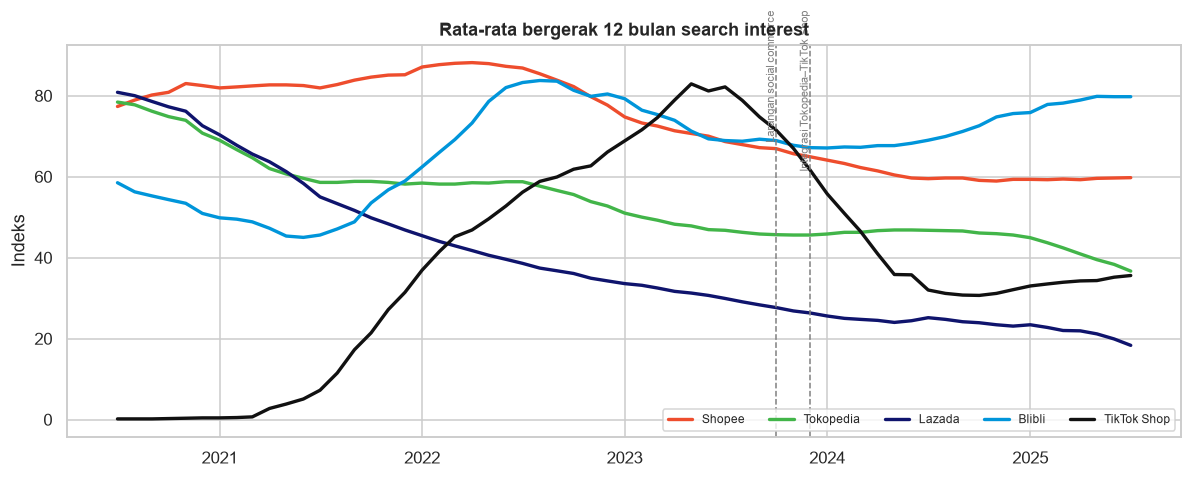

In [6]:
# Gabungan semua platform pada satu grafik (rata-rata bergerak 12 bulan) – bandingkan POLA, bukan level
fig, ax = plt.subplots(figsize=(11, 4.5))
for p in PLATFORMS:
    ax.plot(ts.index, ts[p].rolling(12, center=True).mean(), label=p, color=COLORS[p], lw=2.2)
for name, d in EVENTS.items():
    ax.axvline(pd.Timestamp(d), color="grey", ls="--", lw=1)
    ax.text(pd.Timestamp(d), 101, name.split("(")[0].strip(), rotation=90, va="top", ha="right", fontsize=7, color="grey")
ax.set_title("Rata-rata bergerak 12 bulan search interest"); ax.set_ylabel("Indeks"); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); savefig("A1_tren_gabungan.png"); plt.show()

## A2. Pertumbuhan tahunan (YoY) dan CAGR

,Shopee,Tokopedia,Lazada,Blibli,TikTok Shop
Kode Periode,,,,,
2020,77.3,78.4,80.8,58.5,NaN
2021,81.9,58.6,55.0,45.6,19.8
2022,86.8,58.8,38.6,83.2,56.2
2023,68.7,46.8,29.9,68.9,82.2
2024,59.5,46.8,25.2,69.0,32.0
2025,59.8,36.7,18.3,79.8,35.6


,Shopee,Tokopedia,Lazada,Blibli,TikTok Shop
Tahun,,,,,
2020,nan,nan,nan,nan,nan
2021,5.900000,-25.300000,-32.000000,-22.100000,nan
2022,6.000000,0.300000,-29.800000,82.600000,184.400000
2023,-20.900000,-20.400000,-22.500000,-17.200000,46.300000
2024,-13.300000,0.000000,-15.900000,0.100000,-61.100000
2025,0.400000,-21.600000,-27.200000,15.600000,11.200000


,CAGR (%/tahun),Periode,Catatan
Shopee,-5.0,2020–2025,
Tokopedia,-14.1,2020–2025,
Lazada,-25.7,2020–2025,
Blibli,6.4,2020–2025,
TikTok Shop,15.9,2021–2025,Tahun awal parsial (Sep–Des 2021); interpretas...


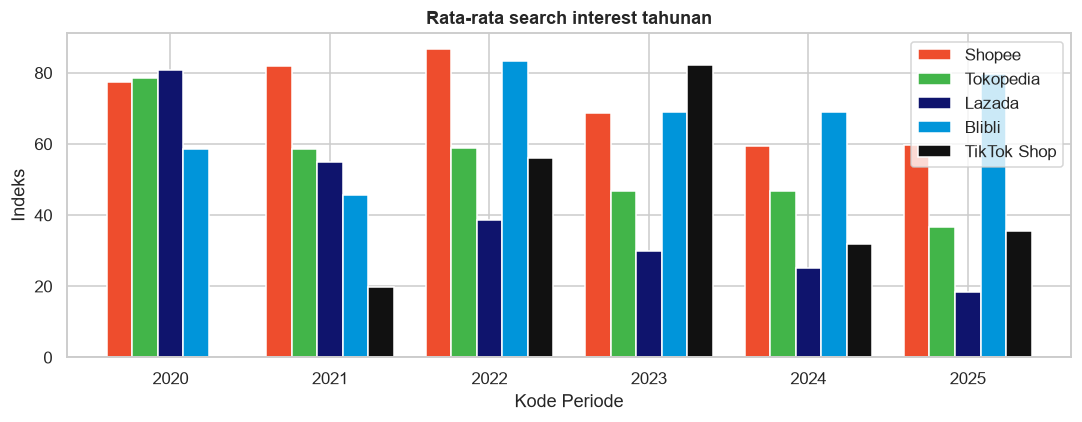

In [7]:
annual = ts[PLATFORMS].groupby(ts.index.year).mean()
# TikTok Shop: rata-rata tahunan hanya dari bulan aktif (>= September 2021).
annual["TikTok Shop"] = series["TikTok Shop"].groupby(series["TikTok Shop"].index.year).mean()
display(annual.round(1))

yoy = annual.pct_change() * 100
display(yoy.round(1).rename_axis("Tahun").style.set_caption("Perubahan YoY rata-rata tahunan (%)"))

def cagr(first, last, n):
    if pd.isna(first) or pd.isna(last) or first <= 0 or last < 0 or n <= 0:
        return np.nan
    return ((last / first) ** (1 / n) - 1) * 100

cg, cagr_notes = {}, {}
for p in PLATFORMS:
    a = annual[p].dropna()
    cg[p] = cagr(a.iloc[0], a.iloc[-1], a.index[-1] - a.index[0])
    cagr_notes[p] = "Tahun awal parsial (Sep–Des 2021); interpretasikan hati-hati" if p == "TikTok Shop" else ""

cagr_df = pd.Series(cg, name="CAGR (%/tahun)").round(1).to_frame()
cagr_df["Periode"] = [f"{annual[p].dropna().index[0]}–{annual[p].dropna().index[-1]}" for p in PLATFORMS]
cagr_df["Catatan"] = [cagr_notes[p] for p in PLATFORMS]
display(cagr_df)

annual.plot(kind="bar", figsize=(10, 4), color=[COLORS[p] for p in PLATFORMS], width=.8)
plt.title("Rata-rata search interest tahunan"); plt.xticks(rotation=0); plt.ylabel("Indeks")
plt.tight_layout(); savefig("A2_rata_tahunan.png"); plt.show()

## A3. Uji tren: Mann-Kendall dan Sen's slope
Uji nonparametrik yang sesuai untuk indeks terbatas 0–100 dan tidak mengasumsikan distribusi normal. `Sen's slope` = perubahan indeks per bulan.

In [8]:
rows = []
for p, s in series.items():
    r = mk.original_test(s.values)
    rows.append({"Platform": p, "n": len(s), "Tren": r.trend, "p-value": r.p, "Kendall tau": r.Tau,
                 "Sen slope (indeks/bln)": r.slope, "Sen slope (indeks/thn)": r.slope * 12})
mk_df = pd.DataFrame(rows).set_index("Platform")
display(mk_df.round(4))

,n,Tren,p-value,Kendall tau,Sen slope (indeks/bln),Sen slope (indeks/thn)
Platform,,,,,,
Shopee,72,decreasing,0.000,-0.5059,-0.4286,-5.1429
Tokopedia,72,decreasing,0.000,-0.7653,-0.5862,-7.0345
Lazada,72,decreasing,0.000,-0.8498,-0.8769,-10.5227
Blibli,72,increasing,0.000,0.4085,0.3867,4.6408
TikTok Shop,52,no trend,0.262,-0.1078,-0.3039,-3.6473


## A4. Pola musiman: dekomposisi STL
Memisahkan **tren**, **musiman** (periode 12 bulan), dan **residu**. Kekuatan musiman (*Fs*) mendekati 1 berarti musiman kuat (Wang et al.). Gunakan untuk melihat efek Ramadan/Lebaran, Harbolnas 11.11 dan 12.12.

Kekuatan musiman (Fs):


,Fs
Shopee,0.122
Tokopedia,0.231
Lazada,0.478
Blibli,0.094
TikTok Shop,0.182


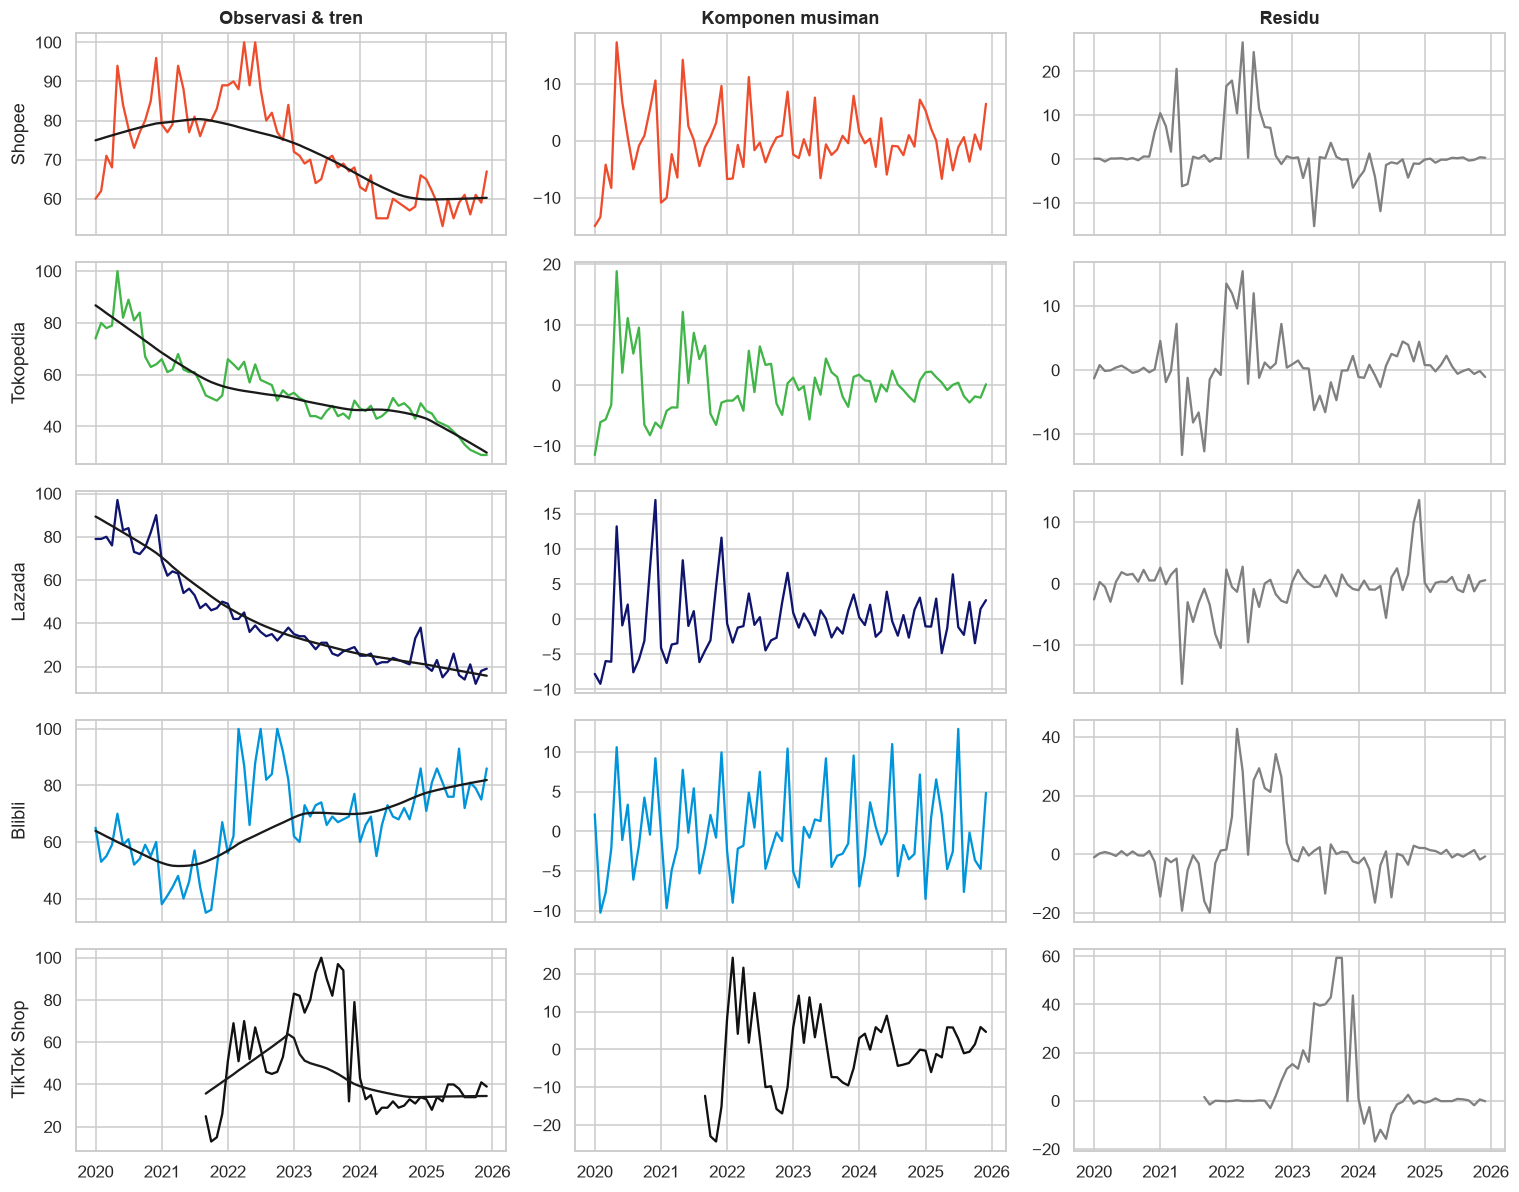

In [9]:
stl_res, strength = {}, {}
for p, s in series.items():
    res = STL(s, period=12, robust=True).fit()
    stl_res[p] = res
    strength[p] = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
print("Kekuatan musiman (Fs):")
display(pd.Series(strength, name="Fs").round(3).to_frame())

fig, axes = plt.subplots(len(PLATFORMS), 3, figsize=(14, 11), sharex="col")
for i, p in enumerate(PLATFORMS):
    r = stl_res[p]
    axes[i, 0].plot(r.observed.index, r.observed, color=COLORS[p]); axes[i, 0].plot(r.trend.index, r.trend, color="k", lw=1.5)
    axes[i, 1].plot(r.seasonal.index, r.seasonal, color=COLORS[p])
    axes[i, 2].plot(r.resid.index, r.resid, color="grey")
    axes[i, 0].set_ylabel(p)
for ax, t in zip(axes[0], ["Observasi & tren", "Komponen musiman", "Residu"]): ax.set_title(t)
plt.tight_layout(); savefig("A4_stl.png"); plt.show()

D:\Interest in Indonesian E-Commerce\.venv\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


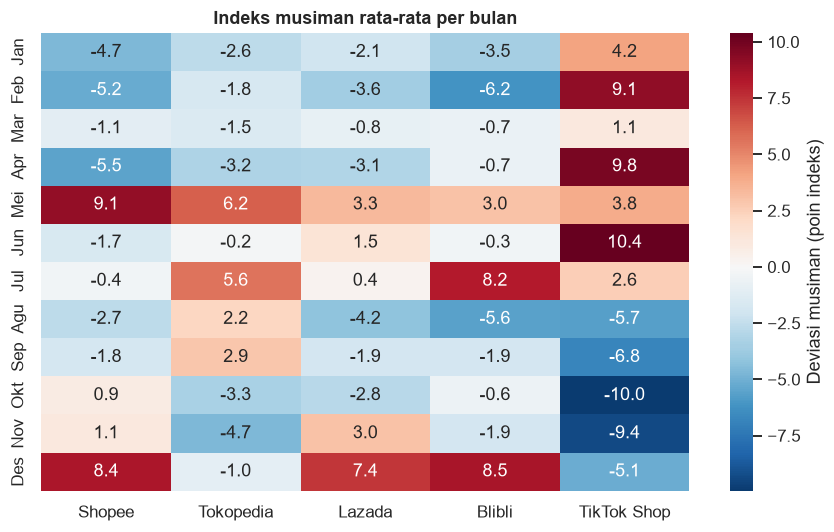

Bulan puncak musiman per platform:


,Bulan tertinggi,Bulan terendah
Shopee,Mei,Apr
Tokopedia,Mei,Nov
Lazada,Des,Agu
Blibli,Des,Feb
TikTok Shop,Jun,Okt


In [10]:
# Indeks musiman rata-rata per bulan (dari komponen musiman STL)
bulan = ["Jan","Feb","Mar","Apr","Mei","Jun","Jul","Agu","Sep","Okt","Nov","Des"]
seas = pd.DataFrame({p: stl_res[p].seasonal.groupby(stl_res[p].seasonal.index.month).mean() for p in PLATFORMS})
seas.index = bulan

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(seas, cmap="RdBu_r", center=0, annot=True, fmt=".1f", cbar_kws={"label": "Deviasi musiman (poin indeks)"}, ax=ax)
ax.set_title("Indeks musiman rata-rata per bulan")
plt.tight_layout(); savefig("A4_indeks_musiman.png"); plt.show()

print("Bulan puncak musiman per platform:")
display(seas.idxmax().to_frame("Bulan tertinggi").join(seas.idxmin().to_frame("Bulan terendah")))

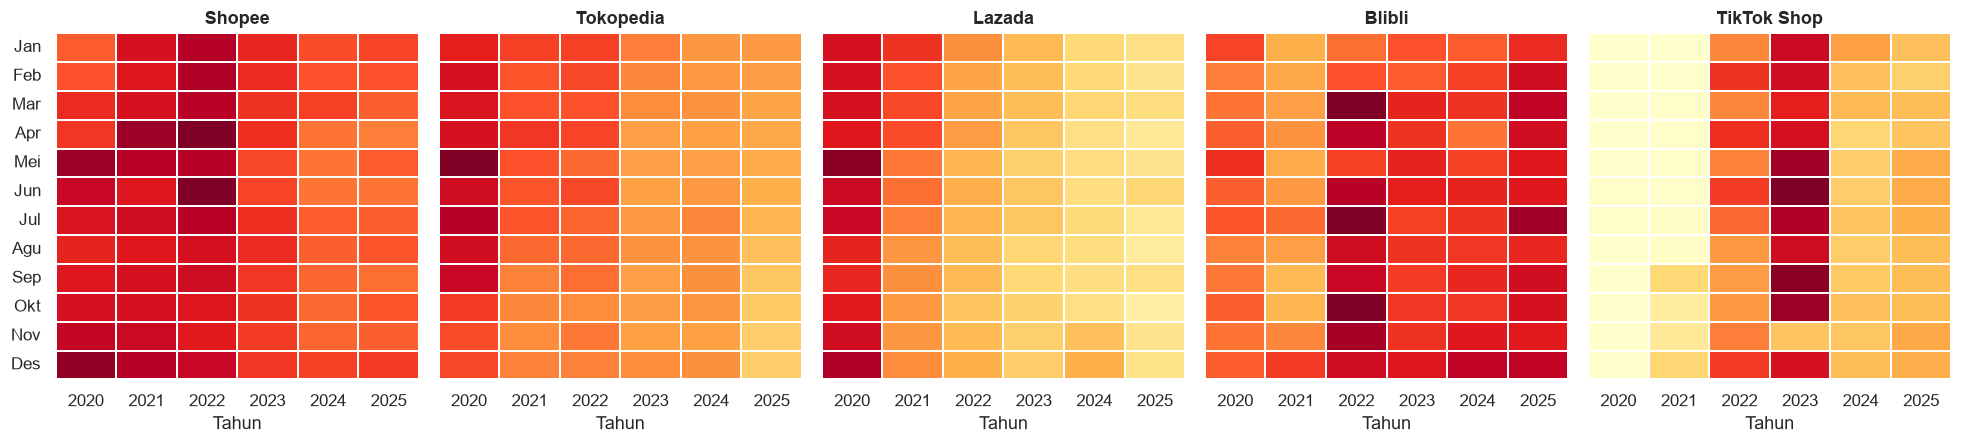

In [11]:
# Heatmap bulan × tahun per platform
fig, axes = plt.subplots(1, len(PLATFORMS), figsize=(18, 4.2), sharey=True)
for ax, p in zip(axes, PLATFORMS):
    piv = ts[p].to_frame("v").assign(Tahun=ts.index.year, Bulan=ts.index.month).pivot(index="Bulan", columns="Tahun", values="v")
    piv.index = bulan
    sns.heatmap(piv, cmap="YlOrRd", vmin=0, vmax=100, ax=ax, cbar=False, linewidths=.3)
    ax.set_title(p); ax.set_ylabel("")
plt.tight_layout(); savefig("A4_heatmap_bulan_tahun.png"); plt.show()

## A5. Perubahan struktural (*structural break*)
Dua pendekatan: (1) **deteksi otomatis** dengan PELT (ruptures) pada rata-rata bergerak 3 bulan untuk mengurangi *noise*, dan (2) **uji Chow** pada tanggal peristiwa yang ditentukan peneliti (`EVENTS`).

Shopee      : ['Feb 2023']
Tokopedia   : ['Nov 2020', 'Mar 2023']
Lazada      : ['Mar 2021', 'Jun 2022']
Blibli      : ['Feb 2022']
TikTok Shop : ['Dec 2022', 'Dec 2023']


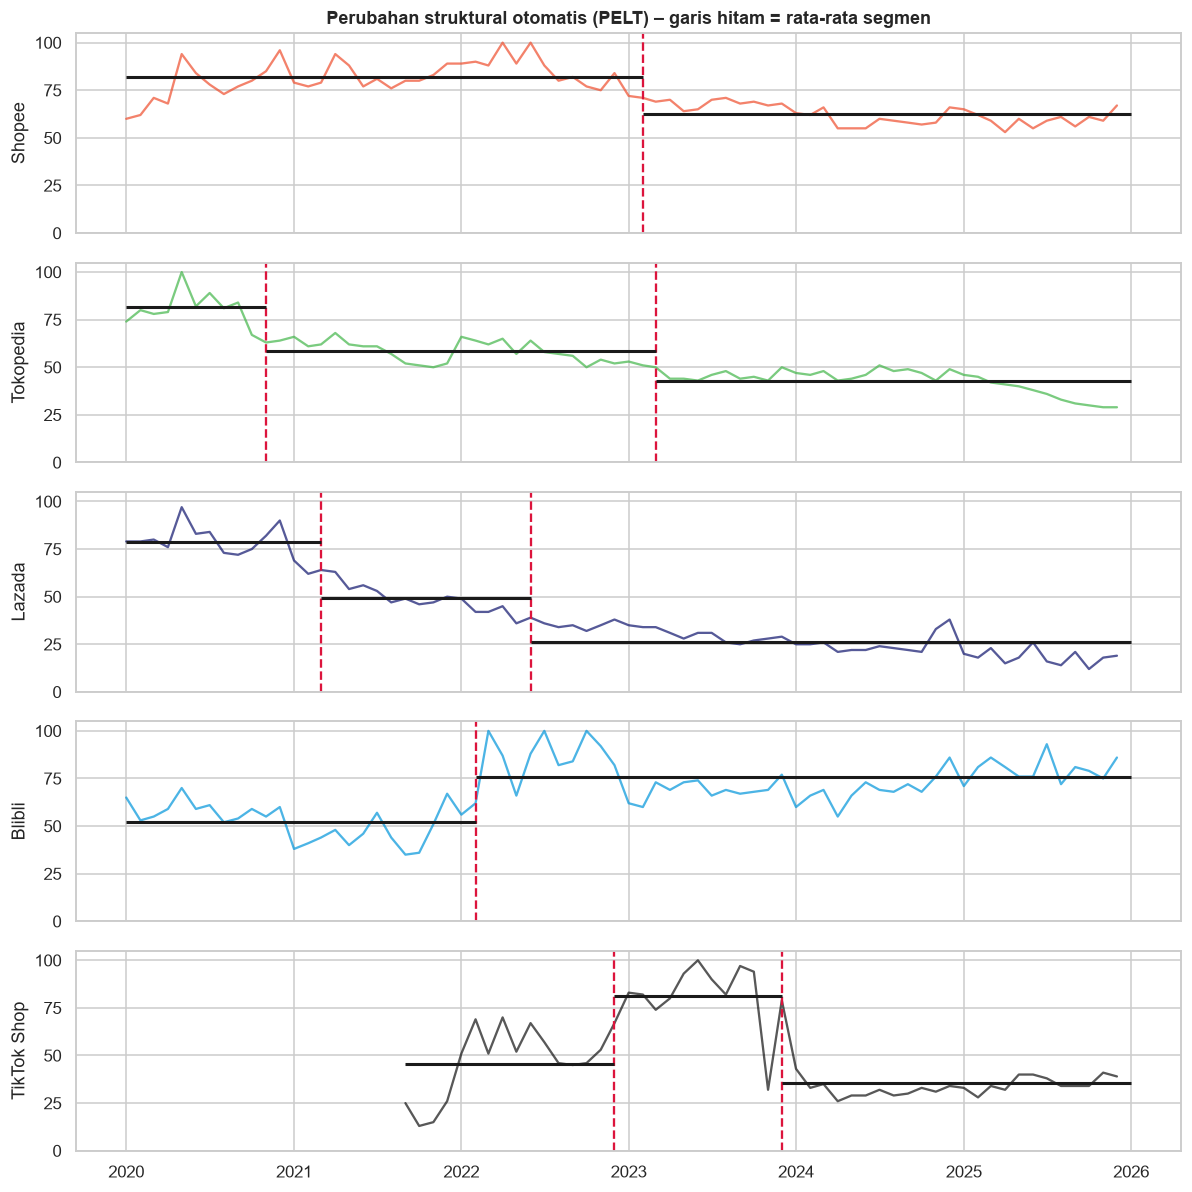

In [12]:
def detect_breaks(s, pen_scale=2.0, min_size=6):
    x = s.rolling(3, center=True, min_periods=1).mean().values.reshape(-1, 1)
    pen = pen_scale * np.log(len(x)) * np.var(x)           # penalti ala BIC; naikkan pen_scale (mis. 3) agar lebih konservatif, turunkan (1) agar lebih sensitif
    algo = rpt.Pelt(model="l2", min_size=min_size, jump=1).fit(x)
    bks = algo.predict(pen=pen)[:-1]                        # buang titik akhir
    return [s.index[b] for b in bks]

breaks = {p: detect_breaks(s) for p, s in series.items()}
for p, b in breaks.items():
    print(f"{p:12s}:", [d.strftime("%b %Y") for d in b] if b else "tidak ada perubahan terdeteksi")

fig, axes = plt.subplots(len(PLATFORMS), 1, figsize=(11, 11), sharex=True)
for ax, p in zip(axes, PLATFORMS):
    s = series[p]
    ax.plot(s.index, s, color=COLORS[p], alpha=.7)
    for d in breaks[p]: ax.axvline(d, color="crimson", ls="--")
    # rata-rata per segmen
    edges = [s.index[0]] + breaks[p] + [s.index[-1] + pd.offsets.MonthBegin(1)]
    for a, b in zip(edges[:-1], edges[1:]):
        seg = s[(s.index >= a) & (s.index < b)]
        ax.hlines(seg.mean(), a, b, color="k", lw=2)
    ax.set_ylabel(p); ax.set_ylim(0, 105)
axes[0].set_title("Perubahan struktural otomatis (PELT) – garis hitam = rata-rata segmen")
plt.tight_layout(); savefig("A5_structural_break.png"); plt.show()

In [13]:
def chow_test(y, bk_date):
    """Uji Chow pada tren linier sebelum dan sesudah tanggal breakpoint yang ditentukan."""
    y = y.dropna()
    bk_date = pd.Timestamp(bk_date)
    idx = int(y.index.searchsorted(bk_date))
    n = len(y)
    k = 2  # intersep dan slope

    if idx < 6 or n - idx < 6:
        return np.nan, np.nan

    t = np.arange(n, dtype=float)

    def ssr(tt, yy):
        X = np.column_stack([np.ones(len(tt)), tt])
        beta = np.linalg.lstsq(X, yy, rcond=None)[0]
        return float(np.sum((yy - X @ beta) ** 2))

    ssr_pooled = ssr(t, y.to_numpy())
    ssr_split = ssr(t[:idx], y.to_numpy()[:idx]) + ssr(t[idx:], y.to_numpy()[idx:])
    df_den = n - 2 * k

    if df_den <= 0 or ssr_split <= 0:
        return np.nan, np.nan

    F = max(0.0, ((ssr_pooled - ssr_split) / k) / (ssr_split / df_den))
    p_value = stats.f.sf(F, k, df_den)
    return F, p_value

rows = []
for ev, d in EVENTS.items():
    for p, s in series.items():
        F, pv = chow_test(s, d)
        rows.append({
            "Peristiwa": ev, "Tanggal": d, "Platform": p, "F": F,
            "p-value": pv,
            "Signifikan (α=5%)": bool(pv < .05) if pd.notna(pv) else False
        })
chow_df = pd.DataFrame(rows)
display(chow_df.round(4))

,Peristiwa,Tanggal,Platform,F,p-value,Signifikan (α=5%)
0,Larangan social commerce (Permendag 31/2023),2023-10-01,Shopee,8.5177,0.0005,True
1,Larangan social commerce (Permendag 31/2023),2023-10-01,Tokopedia,7.1151,0.0016,True
2,Larangan social commerce (Permendag 31/2023),2023-10-01,Lazada,37.0707,0.0000,True
3,Larangan social commerce (Permendag 31/2023),2023-10-01,Blibli,2.8049,0.0675,False
4,Larangan social commerce (Permendag 31/2023),2023-10-01,TikTok Shop,43.7048,0.0000,True
5,Integrasi Tokopedia–TikTok Shop,2023-12-01,Shopee,7.8500,0.0009,True
6,Integrasi Tokopedia–TikTok Shop,2023-12-01,Tokopedia,8.9463,0.0004,True
7,Integrasi Tokopedia–TikTok Shop,2023-12-01,Lazada,33.2435,0.0000,True
8,Integrasi Tokopedia–TikTok Shop,2023-12-01,Blibli,2.2956,0.1085,False
9,Integrasi Tokopedia–TikTok Shop,2023-12-01,TikTok Shop,34.9522,0.0000,True


In [14]:
# Perbandingan rata-rata sebelum vs sesudah peristiwa (Mann-Whitney U) – berguna untuk interpretasi substantif
rows = []
for ev, d in EVENTS.items():
    d = pd.Timestamp(d)
    for p, s in series.items():
        a, b = s[s.index < d], s[s.index >= d]
        if len(a) < 6 or len(b) < 6: continue
        u, pv = stats.mannwhitneyu(a, b, alternative="two-sided")
        rows.append({"Peristiwa": ev, "Platform": p, "Rata2 sebelum": a.mean(), "Rata2 sesudah": b.mean(),
                     "Selisih": b.mean() - a.mean(), "p-value": pv})
display(pd.DataFrame(rows).round(3))

,Peristiwa,Platform,Rata2 sebelum,Rata2 sesudah,Selisih,p-value
0,Larangan social commerce (Permendag 31/2023),Shopee,79.400,60.556,-18.844,0.000
1,Larangan social commerce (Permendag 31/2023),Tokopedia,61.600,42.185,-19.415,0.000
2,Larangan social commerce (Permendag 31/2023),Lazada,52.622,22.444,-30.178,0.000
3,Larangan social commerce (Permendag 31/2023),Blibli,63.578,74.037,10.459,0.001
4,Larangan social commerce (Permendag 31/2023),TikTok Shop,61.360,37.630,-23.730,0.000
5,Integrasi Tokopedia–TikTok Shop,Shopee,78.915,59.960,-18.955,0.000
6,Integrasi Tokopedia–TikTok Shop,Tokopedia,60.851,42.040,-18.811,0.000
7,Integrasi Tokopedia–TikTok Shop,Lazada,51.553,22.040,-29.513,0.000
8,Integrasi Tokopedia–TikTok Shop,Blibli,63.787,74.480,10.693,0.001
9,Integrasi Tokopedia–TikTok Shop,TikTok Shop,61.481,35.600,-25.881,0.000


## A6. Hubungan antarplatform
Korelasi dihitung pada **level** (kecenderungan bergerak bersama) dan pada **selisih bulanan** (*first difference*, menghilangkan efek tren). Periode dibatasi sejak `TIKTOK_START` agar kelima platform sebanding.

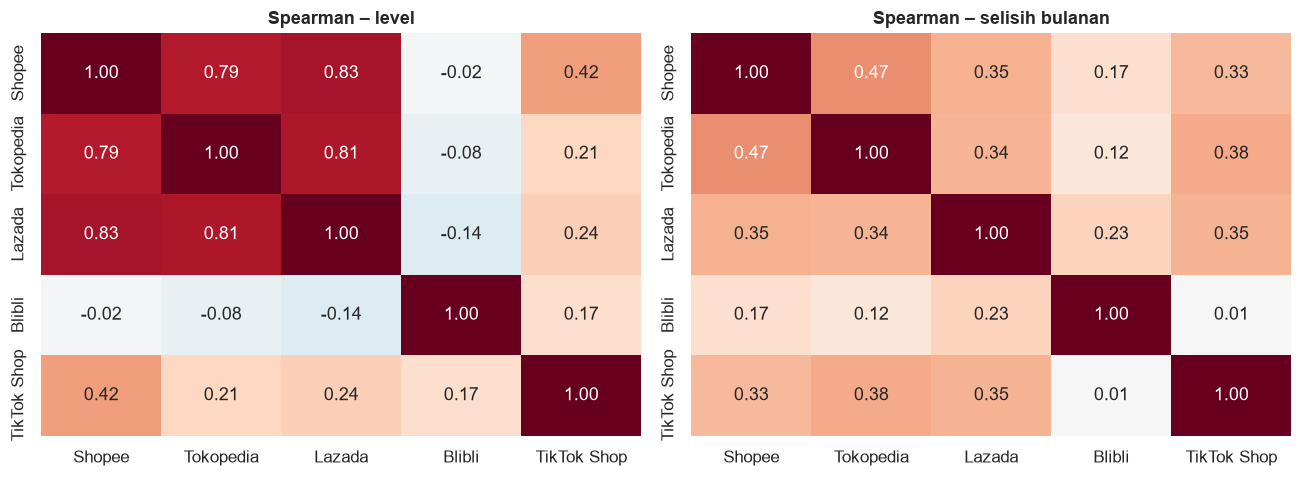

In [15]:
common = ts.loc[TIKTOK_START:, PLATFORMS]
corr_lvl  = common.corr(method="spearman")
corr_diff = common.diff().dropna().corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, c, t in zip(axes, [corr_lvl, corr_diff], ["Spearman – level", "Spearman – selisih bulanan"]):
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(t)
plt.tight_layout(); savefig("A6_korelasi.png"); plt.show()

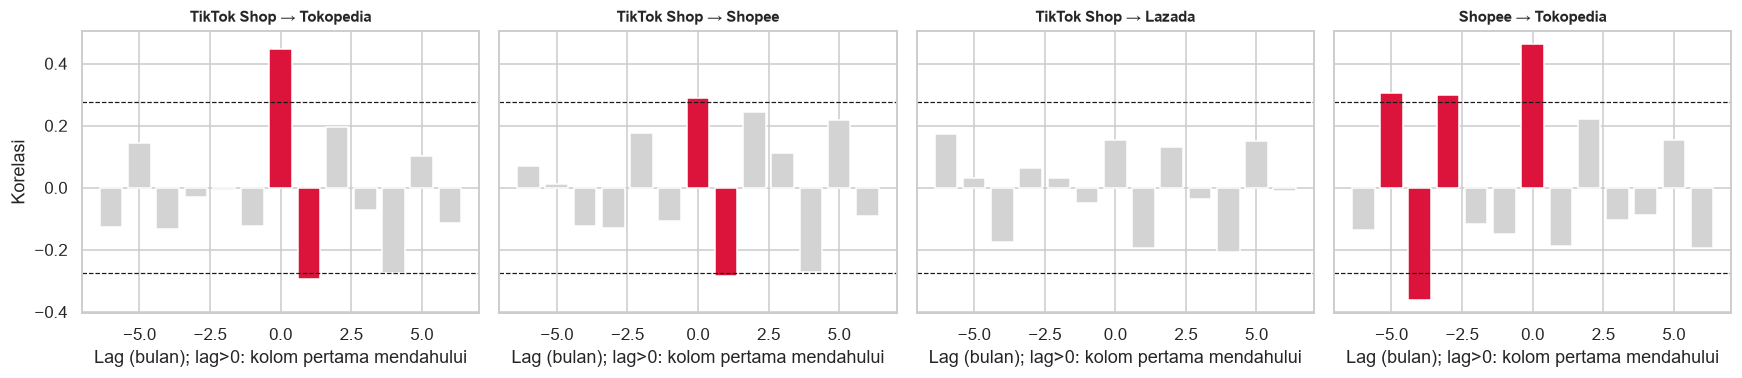

In [16]:
# Cross-correlation pada selisih bulanan: apakah naik/turunnya satu platform mendahului platform lain?
def ccf_table(x, y, max_lag=6):
    dx, dy = x.diff().dropna(), y.diff().dropna()
    out = {}
    for lag in range(-max_lag, max_lag + 1):
        out[lag] = dx.corr(dy.shift(-lag)) if lag != 0 else dx.corr(dy)   # lag>0: x mendahului y
    return pd.Series(out)

pairs = [("TikTok Shop", "Tokopedia"), ("TikTok Shop", "Shopee"), ("TikTok Shop", "Lazada"), ("Shopee", "Tokopedia")]
fig, axes = plt.subplots(1, len(pairs), figsize=(16, 3.6), sharey=True)
n = len(common) - 1; ci = 1.96 / np.sqrt(n)
for ax, (a, b) in zip(axes, pairs):
    cc = ccf_table(common[a], common[b])
    ax.bar(cc.index, cc.values, color=np.where(cc.abs() > ci, "crimson", "lightgrey"))
    ax.axhline(ci, ls="--", c="k", lw=.8); ax.axhline(-ci, ls="--", c="k", lw=.8)
    ax.set_title(f"{a} → {b}", fontsize=10); ax.set_xlabel("Lag (bulan); lag>0: kolom pertama mendahului")
axes[0].set_ylabel("Korelasi")
plt.tight_layout(); savefig("A6_crosscorr.png"); plt.show()

# BAGIAN B — Analisis Regional (34 Provinsi)

> Data regional adalah satu potret agregat (tidak berdimensi waktu) dan setiap platform dinormalisasi sendiri (nilai 100 = provinsi dengan minat tertinggi **untuk platform itu**). Maka bandingkan *posisi relatif provinsi dalam satu platform*, bukan level antarplatform.

## B1. Statistik deskriptif dan peringkat provinsi

In [17]:
display(reg.describe().T.round(2))

top, bottom = {}, {}
for p in PLATFORMS:
    s = reg[p].sort_values(ascending=False)
    top[p]    = [f"{i} ({v:.0f})" for i, v in s.head(5).items()]
    bottom[p] = [f"{i} ({v:.0f})" for i, v in s.tail(5)[::-1].items()]
print("5 provinsi TERTINGGI per platform"); display(pd.DataFrame(top, index=range(1, 6)))
print("5 provinsi TERENDAH per platform");  display(pd.DataFrame(bottom, index=range(1, 6)))

,count,mean,std,min,25%,50%,75%,max
Shopee,34.0,56.35,21.69,21.0,38.00,55.5,69.00,100.0
Tokopedia,34.0,27.85,18.44,12.0,16.50,22.0,29.25,100.0
Lazada,34.0,39.79,20.46,18.0,28.25,33.0,42.50,100.0
Blibli,34.0,37.65,17.59,14.0,28.25,33.5,42.00,100.0
TikTok Shop,34.0,70.29,17.79,38.0,58.50,73.5,78.75,100.0


5 provinsi TERTINGGI per platform


,Shopee,Tokopedia,Lazada,Blibli,TikTok Shop
1,DI Yogyakarta (100),DKI Jakarta (100),Banten (100),DKI Jakarta (100),Jawa Barat (100)
2,Jawa Barat (96),Banten (68),Jawa Barat (97),DI Yogyakarta (68),Aceh (99)
3,Jawa Timur (91),DI Yogyakarta (56),DKI Jakarta (95),Banten (67),Jawa Tengah (98)
4,Jawa Tengah (88),Jawa Barat (51),Jawa Tengah (62),Jawa Barat (60),Jawa Timur (94)
5,DKI Jakarta (87),Jawa Tengah (45),DI Yogyakarta (52),Kepulauan Riau (57),Banten (92)


5 provinsi TERENDAH per platform


,Shopee,Tokopedia,Lazada,Blibli,TikTok Shop
1,Papua (21),Maluku (12),Nusa Tenggara Barat (18),Maluku (14),Maluku (38)
2,Papua Barat (22),Sulawesi Barat (14),Kalimantan Selatan (21),Papua (16),Nusa Tenggara Timur (38)
3,Maluku (25),Nusa Tenggara Timur (14),Papua Barat (23),Maluku Utara (17),Papua Barat (39)
4,Nusa Tenggara Timur (25),Sulawesi Tenggara (14),Kalimantan Barat (24),Papua Barat (20),Papua (40)
5,Maluku Utara (32),Maluku Utara (14),Papua (25),Sulawesi Tenggara (21),Maluku Utara (47)


## B2. Visualisasi sebaran wilayah

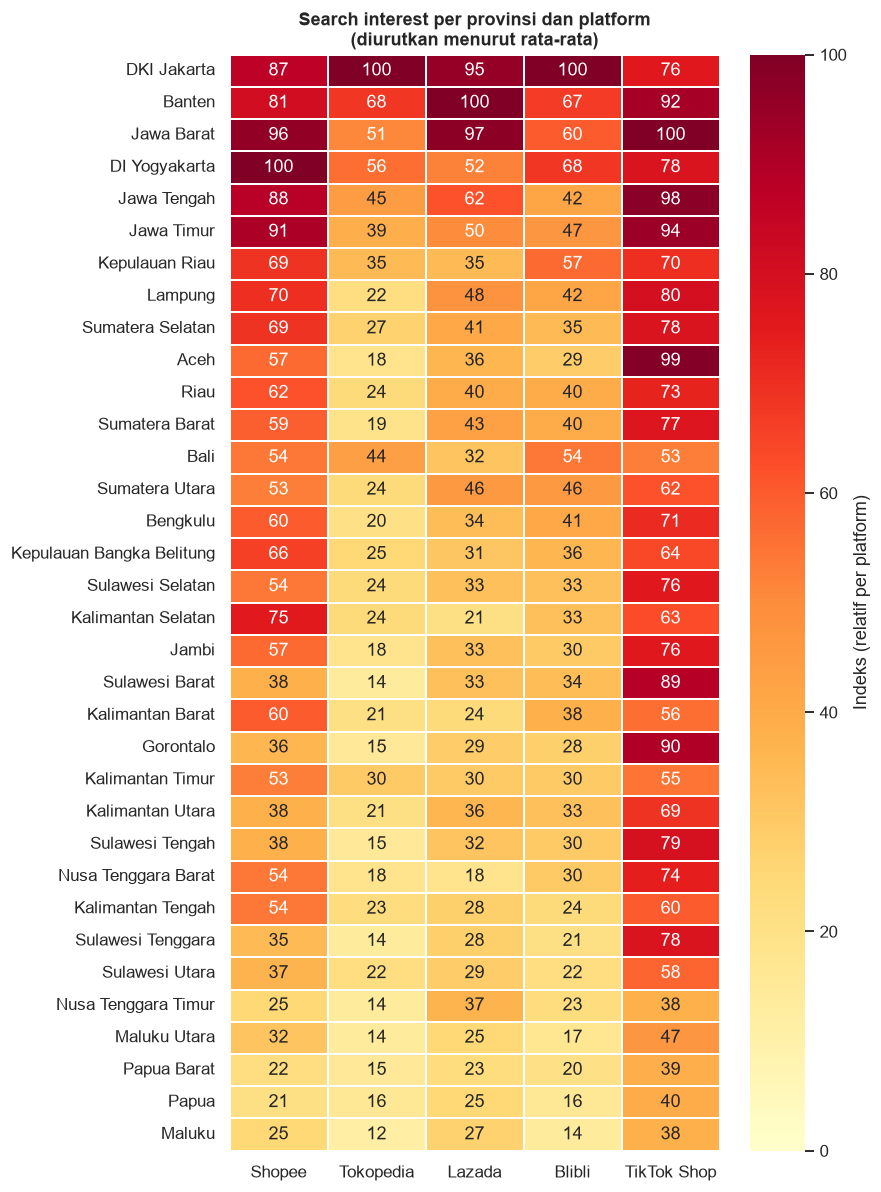

In [18]:
order = reg.mean(axis=1).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 11))
sns.heatmap(reg.loc[order], annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=100, linewidths=.3,
            cbar_kws={"label": "Indeks (relatif per platform)"}, ax=ax)
ax.set_ylabel(""); ax.set_title("Search interest per provinsi dan platform\n(diurutkan menurut rata-rata)")
plt.tight_layout(); savefig("B2_heatmap_provinsi.png"); plt.show()

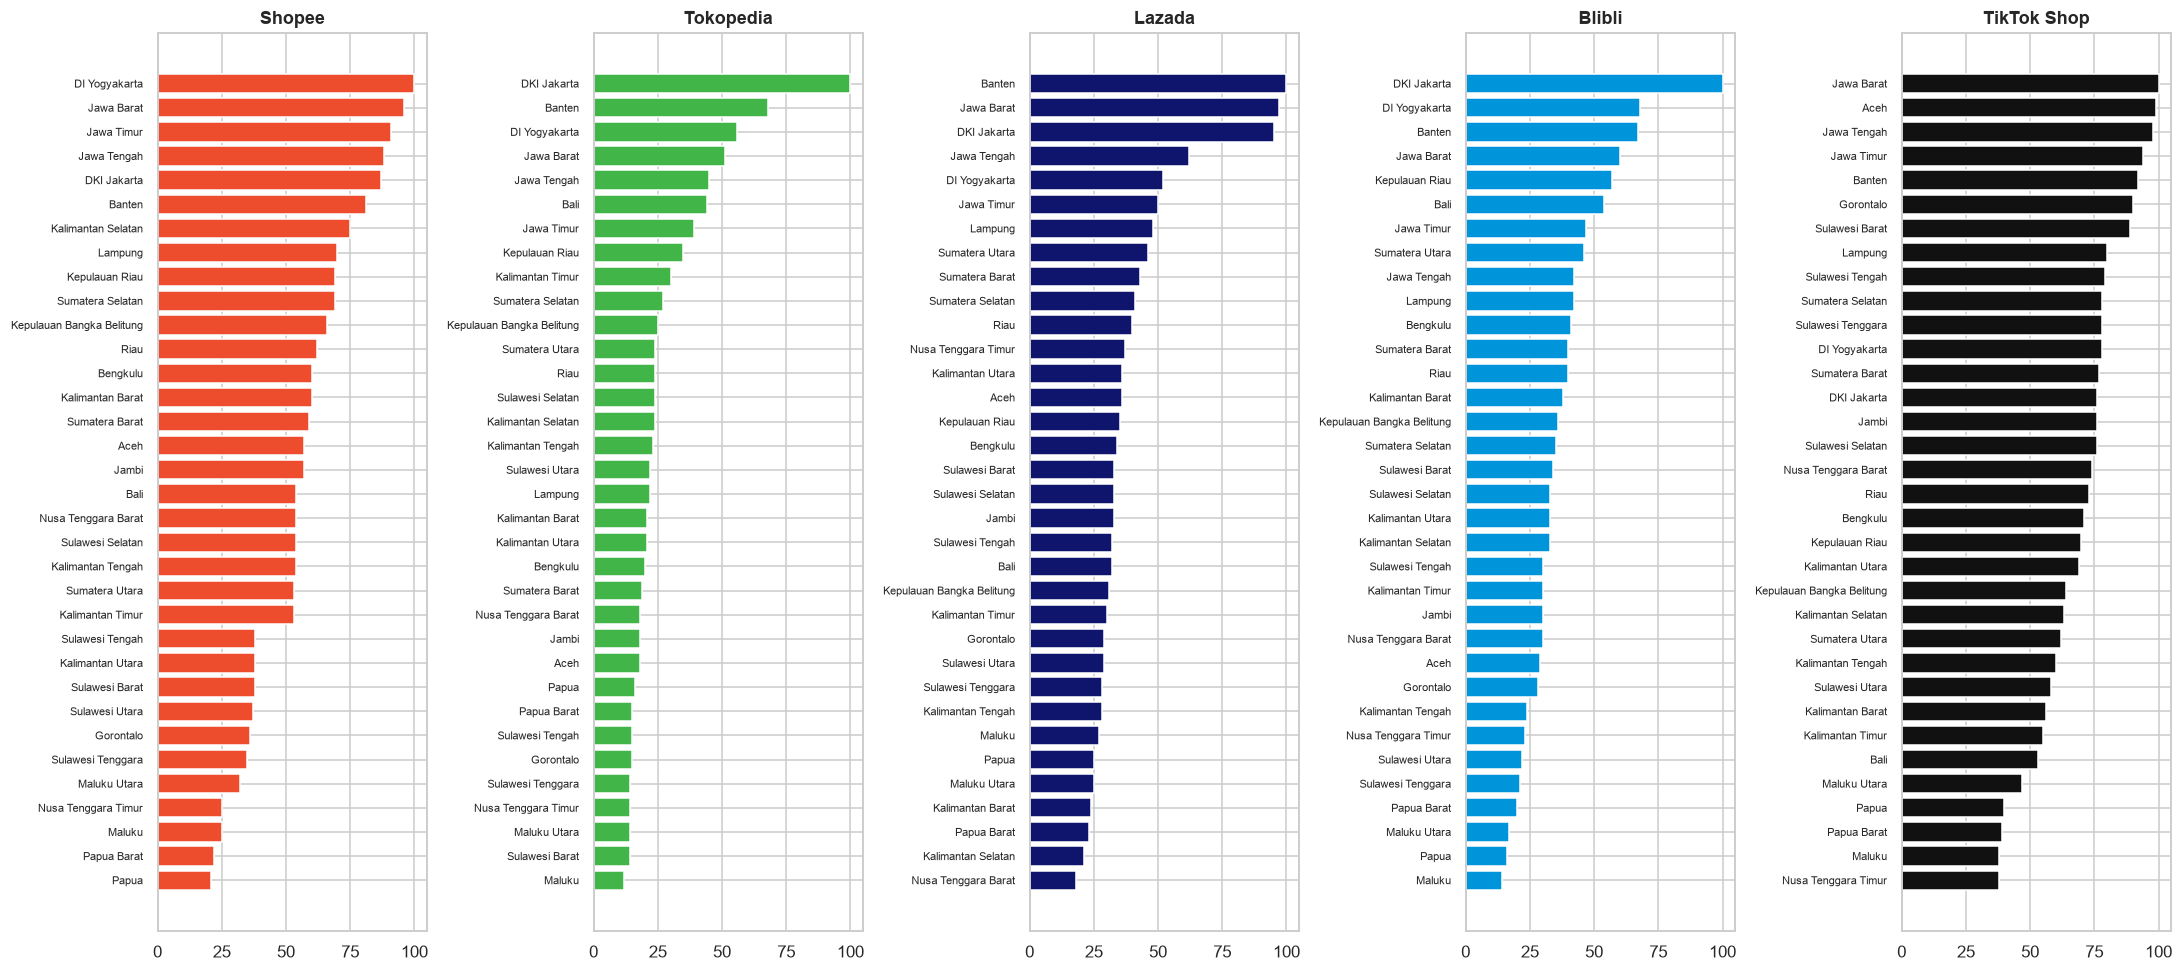

In [19]:
fig, axes = plt.subplots(1, len(PLATFORMS), figsize=(20, 9), sharey=False)
for ax, p in zip(axes, PLATFORMS):
    s = reg[p].sort_values()
    ax.barh(s.index, s.values, color=COLORS[p]); ax.set_title(p); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); savefig("B2_ranking_provinsi.png"); plt.show()

In [20]:
# OPSIONAL – Peta choropleth. Butuh geopandas dan file GeoJSON batas provinsi Indonesia
# (nama provinsi di GeoJSON harus disamakan dengan kolom 'Wilayah').
GEOJSON_PATH = None   # contoh: "indonesia_provinces.geojson"
if GEOJSON_PATH:
    import geopandas as gpd
    gdf = gpd.read_file(GEOJSON_PATH)
    NAME_COL = "PROVINSI"          # sesuaikan nama kolom provinsi di GeoJSON
    fig, axes = plt.subplots(1, len(PLATFORMS), figsize=(24, 5))
    for ax, p in zip(axes, PLATFORMS):
        gdf.merge(reg[[p]], left_on=NAME_COL, right_index=True, how="left").plot(
            column=p, cmap="YlOrRd", legend=True, ax=ax, edgecolor="white", linewidth=.3, missing_kwds={"color": "lightgrey"})
        ax.set_title(p); ax.axis("off")
    plt.tight_layout(); savefig("B2_choropleth.png"); plt.show()
else:
    print("Choropleth dilewati (GEOJSON_PATH belum diisi). Heatmap dan ranking di atas sudah mewakili sebaran wilayah.")

Choropleth dilewati (GEOJSON_PATH belum diisi). Heatmap dan ranking di atas sudah mewakili sebaran wilayah.


## B3. Platform dominan per provinsi

In [21]:
dom = reg.idxmax(axis=1).rename("Platform dominan")
print("Jumlah provinsi per platform dominan:")
display(dom.value_counts().to_frame("Jumlah provinsi"))
display(dom.to_frame().join(reg.max(axis=1).rename("Nilai tertinggi")).sort_values("Platform dominan"))
print("Catatan: karena skala tiap platform relatif, 'dominan' berarti platform dengan indeks tertinggi di provinsi tsb "
      "pada skala masing-masing; gunakan hati-hati jika data belum dari satu kueri perbandingan.")

Jumlah provinsi per platform dominan:


,Jumlah provinsi
Platform dominan,
TikTok Shop,27
Shopee,5
Lazada,1
Tokopedia,1


,Platform dominan,Nilai tertinggi
Wilayah,,
Banten,Lazada,100
Kepulauan Bangka Belitung,Shopee,66
Bali,Shopee,54
DI Yogyakarta,Shopee,100
Kalimantan Selatan,Shopee,75
Kalimantan Barat,Shopee,60
Nusa Tenggara Barat,TikTok Shop,74
Nusa Tenggara Timur,TikTok Shop,38
Papua,TikTok Shop,40


Catatan: karena skala tiap platform relatif, 'dominan' berarti platform dengan indeks tertinggi di provinsi tsb pada skala masing-masing; gunakan hati-hati jika data belum dari satu kueri perbandingan.


## B4. Variasi antarwilayah (koefisien variasi)

,Rata-rata,Std,CV (%),Rentang,IQR
TikTok Shop,70.29,17.79,25.30,62,20.25
Shopee,56.35,21.69,38.49,79,31.00
Blibli,37.65,17.59,46.72,86,13.75
Lazada,39.79,20.46,51.40,82,14.25
Tokopedia,27.85,18.44,66.20,88,12.75


CV lebih tinggi = minat lebih timpang antarprovinsi; CV rendah = lebih merata.


D:\Interest in Indonesian E-Commerce\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
D:\Interest in Indonesian E-Commerce\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
D:\Interest in Indonesian E-Commerce\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
D:\Interest in Indonesian E-Commerce\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3

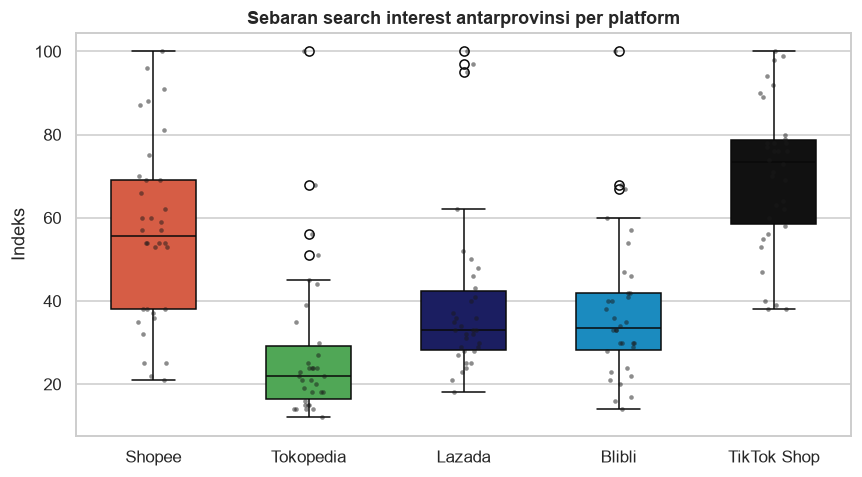

In [22]:
var_df = pd.DataFrame({"Rata-rata": reg.mean(), "Std": reg.std(), "CV (%)": reg.std() / reg.mean() * 100,
                       "Rentang": reg.max() - reg.min(), "IQR": reg.quantile(.75) - reg.quantile(.25)})
display(var_df.round(2).sort_values("CV (%)"))
print("CV lebih tinggi = minat lebih timpang antarprovinsi; CV rendah = lebih merata.")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=reg, palette=COLORS, ax=ax, width=.55); sns.stripplot(data=reg, color="k", size=3, alpha=.5, ax=ax)
ax.set_title("Sebaran search interest antarprovinsi per platform"); ax.set_ylabel("Indeks")
plt.tight_layout(); savefig("B4_boxplot.png"); plt.show()

## B5. Uji perbedaan antarplatform: Friedman + post-hoc Wilcoxon (Holm)
Lima platform diukur pada 34 provinsi yang sama (*repeated measures*) → uji Friedman. Ukuran efek: **Kendall's W** (0–1).

In [23]:
chi2, p = stats.friedmanchisquare(*[reg[c] for c in PLATFORMS])
n, k = reg.shape[0], len(PLATFORMS)
W = chi2 / (n * (k - 1))
print(f"Friedman χ²({k-1}) = {chi2:.2f}, p = {p:.4g}, Kendall's W = {W:.3f}")

rows = []
for a, b in combinations(PLATFORMS, 2):
    differences = reg[a] - reg[b]
    if np.allclose(differences, 0):
        st, pv = 0.0, 1.0
    else:
        st, pv = stats.wilcoxon(reg[a], reg[b], alternative="two-sided", zero_method="wilcox")
    rows.append({"Pasangan": f"{a} vs {b}", "Median A": reg[a].median(),
                 "Median B": reg[b].median(), "W": st, "p": pv})

ph = pd.DataFrame(rows)
ph["p Holm"] = multipletests(ph["p"], method="holm")[1]
ph["Signifikan (α=5%)"] = ph["p Holm"] < .05
display(ph.round(4))

Friedman χ²(4) = 95.35, p = 9.59e-20, Kendall's W = 0.701


,Pasangan,Median A,Median B,W,p,p Holm,Signifikan (α=5%)
0,Shopee vs Tokopedia,55.5,22.0,6.0,0.0000,0.0000,True
1,Shopee vs Lazada,55.5,33.0,54.0,0.0000,0.0001,True
2,Shopee vs Blibli,55.5,33.5,11.0,0.0000,0.0000,True
3,Shopee vs TikTok Shop,55.5,73.5,70.5,0.0001,0.0002,True
4,Tokopedia vs Lazada,22.0,33.0,22.0,0.0000,0.0000,True
5,Tokopedia vs Blibli,22.0,33.5,6.0,0.0000,0.0000,True
6,Tokopedia vs TikTok Shop,22.0,73.5,5.0,0.0000,0.0000,True
7,Lazada vs Blibli,33.0,33.5,182.5,0.3033,0.3033,False
8,Lazada vs TikTok Shop,33.0,73.5,11.0,0.0000,0.0000,True
9,Blibli vs TikTok Shop,33.5,73.5,10.0,0.0000,0.0000,True


## B6. Jawa vs luar Jawa (Mann-Whitney U)

,Median Jawa,Median luar Jawa,U,p-value,Rank-biserial r,p Holm
Platform,,,,,,
Shopee,89.5,54.0,168.0,0.0002,1.0000,0.0008
Tokopedia,53.5,20.5,167.0,0.0002,0.9881,0.0008
Lazada,78.5,32.0,168.0,0.0002,1.0000,0.0008
Blibli,63.5,31.5,162.5,0.0004,0.9345,0.0008
TikTok Shop,93.0,69.5,150.0,0.0031,0.7857,0.0031


D:\Interest in Indonesian E-Commerce\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
D:\Interest in Indonesian E-Commerce\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


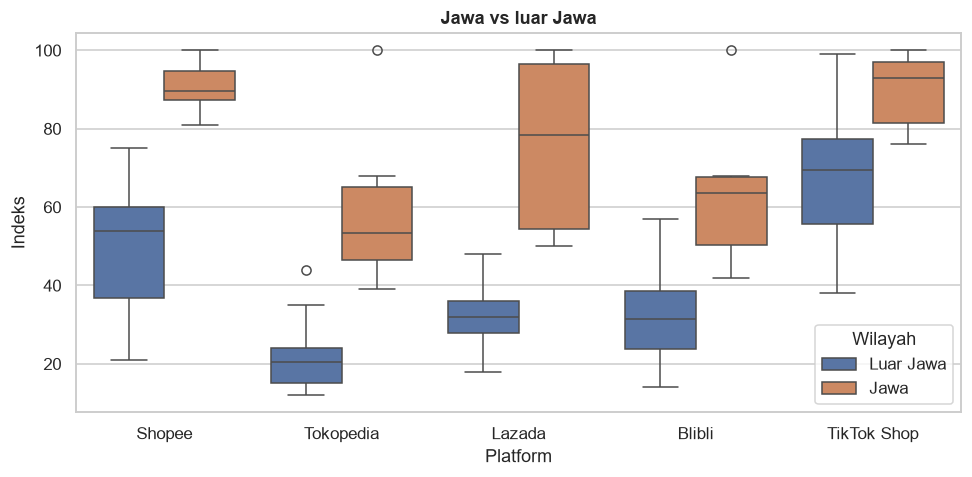

In [24]:
JAWA = ["Banten", "DKI Jakarta", "Jawa Barat", "Jawa Tengah", "DI Yogyakarta", "Jawa Timur"]
missing = [j for j in JAWA if j not in reg.index]
if missing: raise ValueError(f"Nama provinsi Jawa tidak ditemukan pada dataset: {missing}")
is_jawa = reg.index.isin(JAWA)

rows = []
for pf in PLATFORMS:
    a, b = reg.loc[is_jawa, pf], reg.loc[~is_jawa, pf]
    u, pv = stats.mannwhitneyu(a, b, alternative="two-sided")
    rbc = 2 * u / (len(a) * len(b)) - 1          # rank-biserial correlation (ukuran efek)
    rows.append({"Platform": pf, "Median Jawa": a.median(), "Median luar Jawa": b.median(),
                 "U": u, "p-value": pv, "Rank-biserial r": rbc})
jv = pd.DataFrame(rows).set_index("Platform")
jv["p Holm"] = multipletests(jv["p-value"], method="holm")[1]
display(jv.round(4))

melt = reg.assign(Wilayah=np.where(is_jawa, "Jawa", "Luar Jawa")).melt(id_vars="Wilayah", var_name="Platform", value_name="Indeks")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=melt, x="Platform", y="Indeks", hue="Wilayah", palette=["#4C72B0", "#DD8452"], ax=ax)
ax.set_title("Jawa vs luar Jawa"); plt.tight_layout(); savefig("B6_jawa_vs_luar.png"); plt.show()

## B7. Kesamaan pola antarplatform lintas provinsi

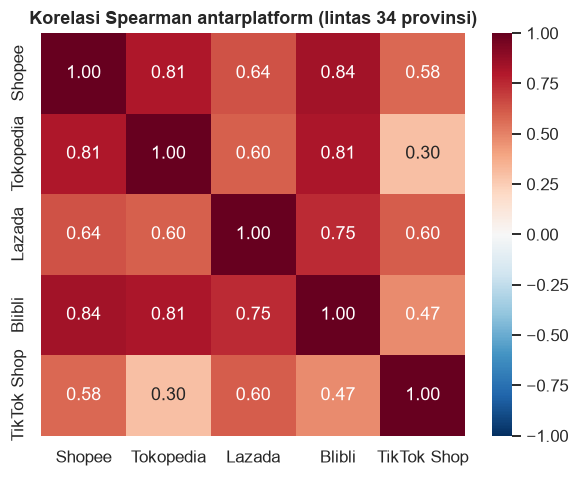

Matriks p-value mentah:


,Shopee,Tokopedia,Lazada,Blibli,TikTok Shop
Shopee,1.0000,0.0000,0.0000,0.0000,0.0004
Tokopedia,0.0000,1.0000,0.0002,0.0000,0.0875
Lazada,0.0000,0.0002,1.0000,0.0000,0.0002
Blibli,0.0000,0.0000,0.0000,1.0000,0.0051
TikTok Shop,0.0004,0.0875,0.0002,0.0051,1.0000


Tabel uji korelasi pasangan dengan koreksi Holm:


,Platform A,Platform B,Spearman rho,p-value,p Holm,Signifikan (p Holm < 0.05)
0,Shopee,Tokopedia,0.8102,0.0000,0.0000,True
1,Shopee,Lazada,0.6392,0.0000,0.0003,True
2,Shopee,Blibli,0.8433,0.0000,0.0000,True
3,Shopee,TikTok Shop,0.5772,0.0004,0.0011,True
4,Tokopedia,Lazada,0.5969,0.0002,0.0008,True
5,Tokopedia,Blibli,0.8132,0.0000,0.0000,True
6,Tokopedia,TikTok Shop,0.2975,0.0875,0.0875,False
7,Lazada,Blibli,0.7480,0.0000,0.0000,True
8,Lazada,TikTok Shop,0.6017,0.0002,0.0008,True
9,Blibli,TikTok Shop,0.4690,0.0051,0.0103,True


In [25]:
corr_reg = reg.corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr_reg, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Korelasi Spearman antarplatform (lintas 34 provinsi)")
plt.tight_layout(); savefig("B7_korelasi_regional.png"); plt.show()

# p-value korelasi: raw p-value dan p-value terkoreksi Holm untuk 10 pasangan unik.
pv = pd.DataFrame(np.eye(len(PLATFORMS)), index=PLATFORMS, columns=PLATFORMS, dtype=float)
pairs = []
for a, b in combinations(PLATFORMS, 2):
    rho, pvalue = stats.spearmanr(reg[a], reg[b])
    pairs.append({"Platform A": a, "Platform B": b, "Spearman rho": rho, "p-value": pvalue})

corr_tests = pd.DataFrame(pairs)
corr_tests["p Holm"] = multipletests(corr_tests["p-value"], method="holm")[1]
corr_tests["Signifikan (p Holm < 0.05)"] = corr_tests["p Holm"] < .05
for _, row in corr_tests.iterrows():
    pv.loc[row["Platform A"], row["Platform B"]] = row["p-value"]
    pv.loc[row["Platform B"], row["Platform A"]] = row["p-value"]

print("Matriks p-value mentah:")
display(pv.round(4))
print("Tabel uji korelasi pasangan dengan koreksi Holm:")
display(corr_tests.round(4))

# BAGIAN C — Ringkasan Terpadu dan Ekspor

In [26]:
summary = pd.DataFrame(index=PLATFORMS)
summary["Tren (Mann-Kendall)"]      = mk_df["Tren"]
summary["Sen slope (indeks/thn)"]   = mk_df["Sen slope (indeks/thn)"].round(2)
summary["CAGR (%)"]                 = cagr_df["CAGR (%/tahun)"]
summary["Kekuatan musiman (Fs)"]    = pd.Series(strength).round(2)
summary["Bulan puncak musiman"]     = seas.idxmax()
summary["Break terdeteksi"]         = [", ".join(d.strftime("%b %Y") for d in breaks[p]) or "-" for p in PLATFORMS]
summary["Rata2 regional"]           = reg.mean().round(1)
summary["CV regional (%)"]          = var_df["CV (%)"].round(1)
summary["Provinsi tertinggi"]       = [reg[p].idxmax() for p in PLATFORMS]
summary["Jumlah provinsi dominan"]  = dom.value_counts().reindex(PLATFORMS).fillna(0).astype(int)
display(summary)

,Tren (Mann-Kendall),Sen slope (indeks/thn),CAGR (%),Kekuatan musiman (Fs),Bulan puncak musiman,Break terdeteksi,Rata2 regional,CV regional (%),Provinsi tertinggi,Jumlah provinsi dominan
Shopee,decreasing,-5.14,-5.0,0.12,Mei,Feb 2023,56.4,38.5,DI Yogyakarta,5
Tokopedia,decreasing,-7.03,-14.1,0.23,Mei,"Nov 2020, Mar 2023",27.9,66.2,DKI Jakarta,1
Lazada,decreasing,-10.52,-25.7,0.48,Des,"Mar 2021, Jun 2022",39.8,51.4,Banten,1
Blibli,increasing,4.64,6.4,0.09,Des,Feb 2022,37.6,46.7,DKI Jakarta,0
TikTok Shop,no trend,-3.65,15.9,0.18,Jun,"Dec 2022, Dec 2023",70.3,25.3,Jawa Barat,27


In [27]:
xlsx_path = os.path.join(OUT_DIR, "hasil_analisis.xlsx")
with pd.ExcelWriter(xlsx_path) as w:
    summary.to_excel(w, sheet_name="Ringkasan")
    desc.round(3).to_excel(w, sheet_name="A1_Deskriptif")
    annual.round(2).to_excel(w, sheet_name="A2_Tahunan")
    yoy.round(2).to_excel(w, sheet_name="A2_YoY")
    mk_df.round(4).to_excel(w, sheet_name="A3_MannKendall")
    seas.round(2).to_excel(w, sheet_name="A4_Musiman")
    chow_df.round(4).to_excel(w, sheet_name="A5_Chow", index=False)
    corr_lvl.round(3).to_excel(w, sheet_name="A6_Korelasi_Level")
    corr_diff.round(3).to_excel(w, sheet_name="A6_Korelasi_Diff")
    reg.describe().T.round(2).to_excel(w, sheet_name="B1_Deskriptif")
    var_df.round(2).to_excel(w, sheet_name="B4_Variasi")
    ph.round(4).to_excel(w, sheet_name="B5_PostHoc", index=False)
    jv.round(4).to_excel(w, sheet_name="B6_Jawa_vs_Luar")
    corr_reg.round(3).to_excel(w, sheet_name="B7_Korelasi")
    pv.round(4).to_excel(w, sheet_name="B7_pValue")
    corr_tests.round(4).to_excel(w, sheet_name="B7_UjiPasangan", index=False)
print("Tersimpan di folder:", os.path.abspath(OUT_DIR))

Tersimpan di folder: D:\Interest in Indonesian E-Commerce\output_analisis


## Panduan interpretasi untuk bab Hasil dan Pembahasan

- **Tren (A3):** laporkan arah, *p-value*, dan Sen's slope per tahun. Jangan membandingkan besar slope antarplatform bila skala belum sebanding.
- **Musiman (A4):** sebut bulan puncak dan kaitkan dengan kalender belanja (Ramadan/Lebaran, 11.11, 12.12, Harbolnas).
- **Break (A5):** hasil PELT bersifat eksploratif; uji Chow menguji tanggal yang Anda tentukan berdasarkan teori/peristiwa. Tampilkan keduanya.
- **Korelasi (A6):** korelasi bukan kausalitas. Korelasi negatif TikTok Shop–Tokopedia/Lazada hanya mengindikasikan pola bergerak berlawanan.
- **Regional (B):** gunakan untuk menggambarkan *di mana* minat relatif tinggi pada tiap platform; peringkat provinsi lebih aman ditafsirkan daripada level antarplatform.
- **Keterbatasan:** Google Trends adalah sampel pencarian, bukan penjualan; indeks relatif; hasil dapat sedikit berbeda tiap unduhan; kata kunci "Shopee" dsb. dapat mencerminkan pencarian navigasi, bukan niat membeli.